# Results notebook: conformal false-alarm calibration under shift

CPU only: no GPU, no VisA, no network. It reads the committed CSVs in `results/phase3/` and
`results/phase4/` (made by `python -m anomcal.phase3`, `phase4`, `phase4m`), prints the headline
tables and redraws the main figures. Every number is **measured** (from the real laptop scores);
the only estimates are labelled in `docs/RESULTS_SUMMARY.md`.

Level **0.5** on the x axes is an extra mild level we defined (stored as `severity = -1`), not an ImageNet-C level.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results" / "phase4").is_dir())
P3, P4 = root / "results" / "phase3", root / "results" / "phase4"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
FAMILIES = ["brightness", "gaussian_blur", "gaussian_noise", "jpeg_compression"]
METHODS = ["baseline", "dinov2_knn", "patchcore"]
print("repo root:", root.name)

repo root: anomaly-calibration


## 1. Clean data (Phase 3): does split conformal hit its target?

In [2]:
s3 = pd.read_csv(P3 / "summary_by_method.csv")
t = s3[
    [
        "method",
        "kind",
        "alpha",
        "far_pooled",
        "far_theory_mean",
        "share_far_above_alpha",
        "share_far_above_alpha_theory",
        "tpr_mean",
    ]
].round(4)
print(t.to_string(index=False))
cert = pd.read_csv(P3 / "certifiability.csv")
print(
    "\nnot certifiable at alpha = 1% (tolerance limit):",
    (cert["tolerance_0.01"] == "not_certifiable").all(),
)

    method      kind  alpha  far_pooled  far_theory_mean  share_far_above_alpha  share_far_above_alpha_theory  tpr_mean
  baseline conformal   0.01      0.0073           0.0071                 0.2925                        0.2853    0.1952
  baseline conformal   0.05      0.0469           0.0458                 0.4164                        0.4056    0.3907
  baseline conformal   0.10      0.0975           0.0961                 0.4453                        0.4317    0.5139
  baseline tolerance   0.05      0.0275           0.0261                 0.0886                        0.0868    0.3135
  baseline tolerance   0.10      0.0692           0.0663                 0.1092                        0.0991    0.4498
dinov2_knn conformal   0.01      0.0071           0.0071                 0.2931                        0.2853    0.3759
dinov2_knn conformal   0.05      0.0461           0.0458                 0.4042                        0.4056    0.6433
dinov2_knn conformal   0.10      0.0965 

## 2. Shift (Phase 4): headline table, split conformal, alpha = 5%

A = clean-calibrated threshold on corrupted test normals; B = recalibrated on corrupted calibration normals. Cell = FAR (excess FAR = FAR - alpha); TPR on the corrupted anomalies.

In [3]:
hl = pd.read_csv(P4 / "headline.csv")
x = hl[(hl.kind == "conformal") & (hl.alpha == 0.05) & (hl.corruption != "none")]
rows = []
for c in FAMILIES:
    for m in METHODS:
        row = {"corruption": c, "method": m}
        for s, tag in (("A_no_recal", "A"), ("B_recal", "B")):
            for lv in (0.5, 1, 3, 5):
                r = x[
                    (x.corruption == c) & (x.method == m) & (x.setting == s) & (x.level == lv)
                ].iloc[0]
                row[f"{tag} lvl {lv:g}"] = f"{r.far:.3f} ({r.excess:+.3f})"
        r5 = x[
            (x.corruption == c) & (x.method == m) & (x.setting == "B_recal") & (x.level == 5)
        ].iloc[0]
        row["TPR B lvl 5"] = round(r5.tpr, 2)
        rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

      corruption     method      A lvl 0.5        A lvl 1        A lvl 3        A lvl 5      B lvl 0.5        B lvl 1        B lvl 3        B lvl 5  TPR B lvl 5
      brightness   baseline 0.183 (+0.133) 0.494 (+0.444) 0.993 (+0.943) 1.000 (+0.950) 0.045 (-0.005) 0.046 (-0.004) 0.045 (-0.005) 0.046 (-0.004)         0.14
      brightness dinov2_knn 0.053 (+0.003) 0.104 (+0.054) 0.422 (+0.372) 0.773 (+0.723) 0.045 (-0.005) 0.045 (-0.005) 0.046 (-0.004) 0.046 (-0.004)         0.22
      brightness  patchcore 0.095 (+0.045) 0.279 (+0.229) 0.951 (+0.901) 1.000 (+0.950) 0.046 (-0.004) 0.046 (-0.004) 0.046 (-0.004) 0.046 (-0.004)         0.28
   gaussian_blur   baseline 0.142 (+0.092) 0.955 (+0.905) 1.000 (+0.950) 1.000 (+0.950) 0.045 (-0.005) 0.046 (-0.004) 0.046 (-0.004) 0.046 (-0.004)         0.09
   gaussian_blur dinov2_knn 0.051 (+0.001) 0.160 (+0.110) 0.985 (+0.935) 1.000 (+0.950) 0.045 (-0.005) 0.045 (-0.005) 0.046 (-0.004) 0.045 (-0.005)         0.12
   gaussian_blur  patchcore 0.058 

## 3. Figures (Phase 4)

FAR versus level for Setting A, and before/after recalibration (FAR top, TPR bottom).

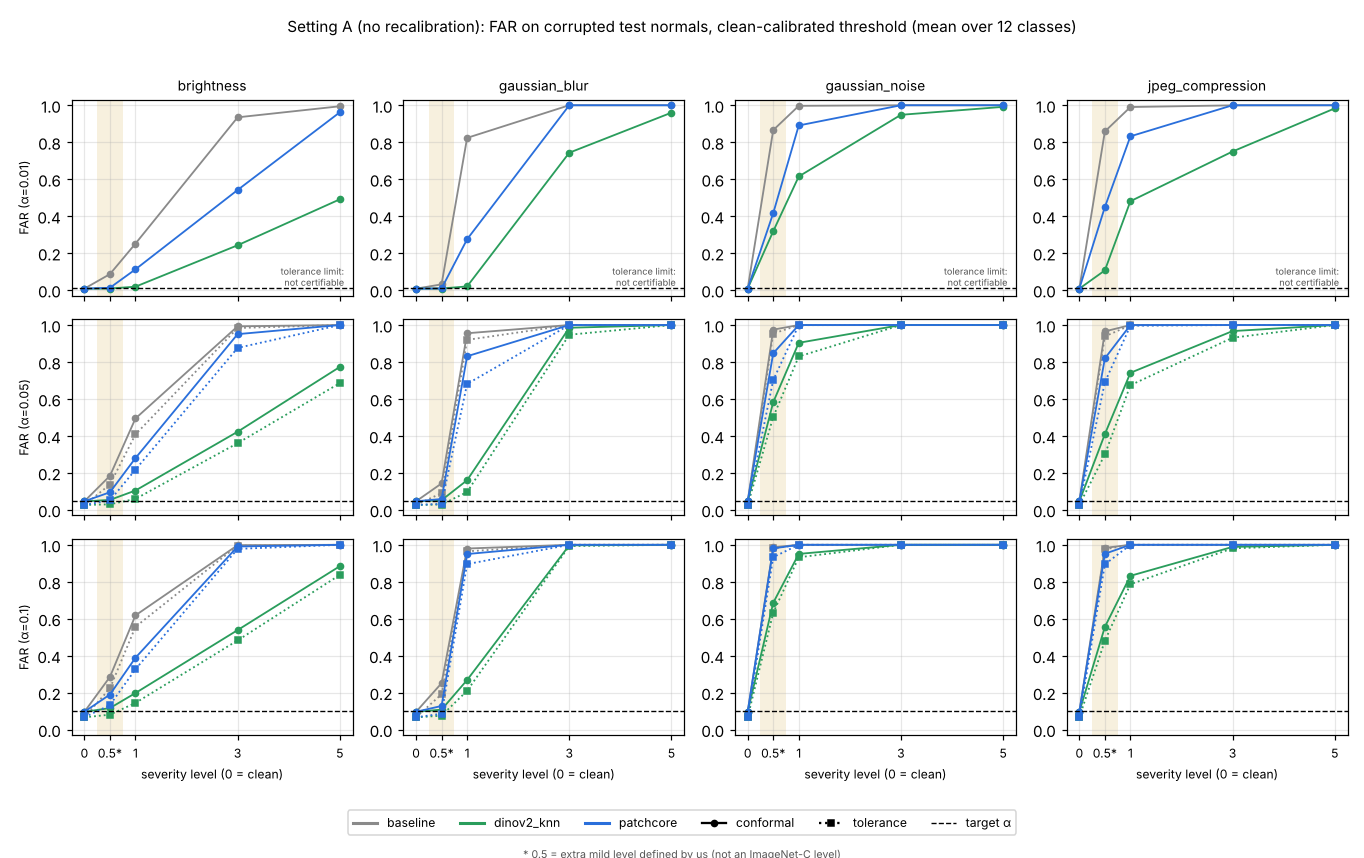

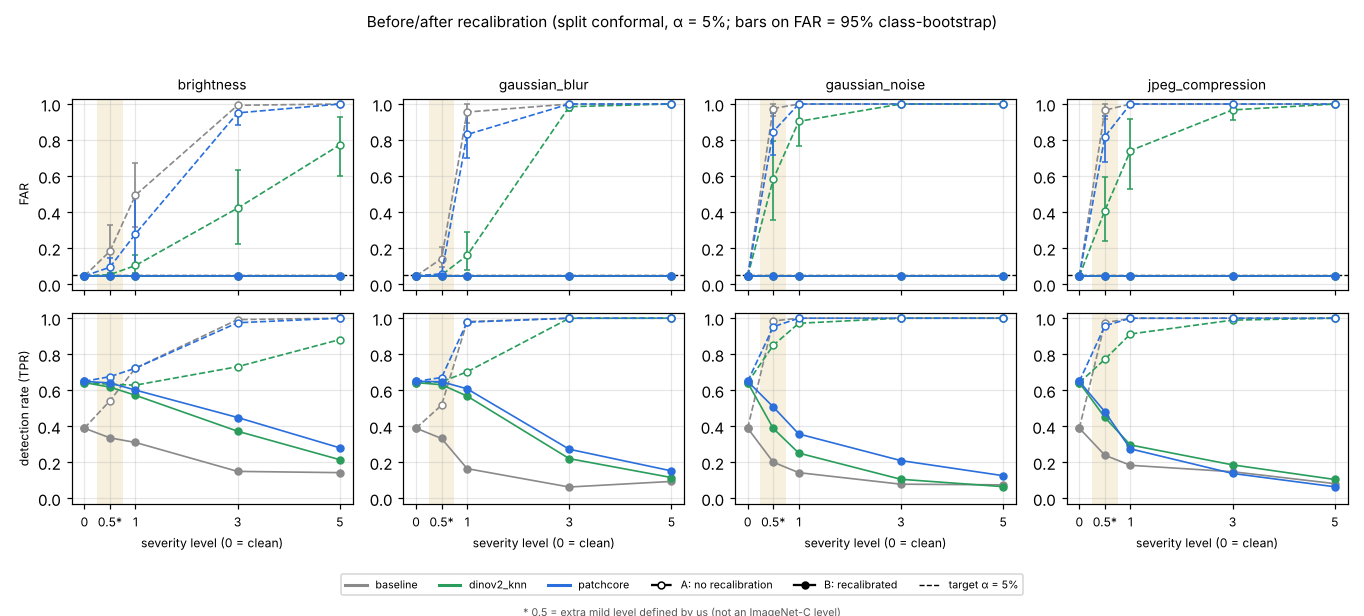

In [4]:
from anomcal.phase4 import make_figures

try:
    from IPython.display import Image, display
except ImportError:  # plain Python (e.g. the test suite): just list the files
    display = None

tmp = Path(tempfile.mkdtemp())
for f in make_figures(hl, tmp):
    display(Image(filename=str(f))) if display else print("figure:", f.name)

## 4. Which method is most stable? (RMS of FAR - alpha; smaller = closer to the target)

Ranking per setting and grid (`all` = 16 shifted conditions incl. level 0.5, `1-3-5` = ImageNet-C levels only), then the **paired** method differences with a class-bootstrap interval.

In [5]:
st = pd.read_csv(P4 / "stability.csv")
a5 = st[(st.setting == "A_no_recal") & (st.kind == "conformal") & (st.alpha == 0.05)]
print(
    a5[["grid", "method", "rms_excess", "rms_lo", "rms_hi", "rank", "class_spread", "seed_spread"]]
    .round(3)
    .to_string(index=False)
)
pr = pd.read_csv(P4 / "paired_stability.csv")
pa = pr[(pr.setting == "A_no_recal") & (pr.kind == "conformal") & (pr.alpha == 0.05)]
print("\nPaired differences, Setting A, conformal alpha = 5% (negative = a closer):")
print(
    pa[["grid", "method_a", "method_b", "diff", "diff_lo", "diff_hi", "excludes_zero"]]
    .round(3)
    .to_string(index=False)
)
print(
    "\nSetting A, all kinds/alphas: paired interval excludes 0 in",
    int(pr[pr.setting == "A_no_recal"].excludes_zero.sum()),
    "of",
    int((pr.setting == "A_no_recal").sum()),
    "cells",
)
print(
    "Setting B: largest |difference| in RMS excess =",
    round(pr[pr.setting == "B_recal"]["diff"].abs().max(), 5),
)

 grid     method  rms_excess  rms_lo  rms_hi  rank  class_spread  seed_spread
  all   baseline       0.863   0.851   0.877     3         0.058        0.005
  all dinov2_knn       0.721   0.681   0.757     1         0.155        0.012
  all  patchcore       0.833   0.818   0.849     2         0.079        0.010
1-3-5   baseline       0.919   0.911   0.930     3         0.038        0.003
1-3-5 dinov2_knn       0.799   0.766   0.828     1         0.143        0.011
1-3-5  patchcore       0.902   0.891   0.913     2         0.058        0.006

Paired differences, Setting A, conformal alpha = 5% (negative = method_a closer to the target):
 grid   method_a  method_b   diff  diff_lo  diff_hi  excludes_zero
  all dinov2_knn patchcore -0.112   -0.142   -0.085           True
  all dinov2_knn  baseline -0.142   -0.179   -0.110           True
  all  patchcore  baseline -0.030   -0.044   -0.017           True
1-3-5 dinov2_knn patchcore -0.103   -0.137   -0.076           True
1-3-5 dinov2_knn  base

## 5. Per-class check (the average can hide a class)

Setting A at the mild level (0.5), conformal alpha = 5%: per-class FAR range.

In [6]:
pc = pd.read_csv(P4 / "per_class.csv")
q = pc[
    (pc.kind == "conformal")
    & (pc.alpha == 0.05)
    & (pc.setting == "A_no_recal")
    & (pc.severity == -1)
]
g = q.groupby(["corruption", "method"]).far.agg(["mean", "min", "max"]).round(3)
g["classes > 10%"] = q.groupby(["corruption", "method"]).far.apply(lambda v: int((v > 0.10).sum()))
print(g.to_string())

                              mean    min    max  classes > 10%
corruption       method                                        
brightness       baseline    0.183  0.040  0.826              6
                 dinov2_knn  0.053  0.041  0.084              0
                 patchcore   0.095  0.049  0.340              2
gaussian_blur    baseline    0.142  0.060  0.390              6
                 dinov2_knn  0.051  0.041  0.067              0
                 patchcore   0.058  0.048  0.072              0
gaussian_noise   baseline    0.975  0.749  1.000             12
                 dinov2_knn  0.582  0.063  1.000             10
                 patchcore   0.847  0.372  1.000             12
jpeg_compression baseline    0.966  0.791  1.000             12
                 dinov2_knn  0.409  0.055  0.917              9
                 patchcore   0.819  0.304  1.000             12


## 6. Recalibration with only m corrupted normals (Phase 4b; levels 1/3/5 only)

In [7]:
sm = pd.read_csv(P4 / "small_m_headline.csv")
g = (
    sm.groupby(["kind", "alpha", "m"])[
        ["far", "law_far", "violation_rate", "law_violation_rate", "tpr"]
    ]
    .mean()
    .round(4)
)
print(g.to_string())
print(
    "\nObserved FAR equals the exact Beta-binomial mean to",
    round((sm.far - sm.law_far).abs().max(), 4),
)

                        far  law_far  violation_rate  law_violation_rate     tpr
kind      alpha m                                                               
conformal 0.01  100  0.0099   0.0099          0.3732              0.3735  0.1290
          0.05  25   0.0384   0.0385          0.2921              0.2920  0.1989
                50   0.0392   0.0392          0.3053              0.3047  0.2098
                100  0.0494   0.0495          0.4563              0.4564  0.2332
          0.10  10   0.0909   0.0909          0.3521              0.3524  0.2730
                25   0.0768   0.0769          0.2817              0.2823  0.2663
                50   0.0980   0.0980          0.4385              0.4388  0.2992
                100  0.0989   0.0990          0.4593              0.4606  0.3024
tolerance 0.05  100  0.0198   0.0198          0.0668              0.0664  0.1678
          0.10  50   0.0392   0.0392          0.0471              0.0471  0.2098
                100  0.0494 